# 02 · Exploratory analysis — first batch

The first collected batch is currently batch 0. All plots use saved data.

## Imports

In [1]:
import json
import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', 30)


## Load batch

In [2]:
DATA = Path('../data')
GROUP = int(os.environ['DATA_API_GROUP'])
files = sorted(DATA.glob(f'group-{GROUP}-*.json'))
if not files:
    raise FileNotFoundError('Collect a batch in notebook 01 first.')
with files[0].open() as file:
    batch = json.load(file)
df = pd.DataFrame(batch['data'])
print(f"Group {GROUP} | batch {batch['batch_number']} | {len(df):,} rows")


Group 4 | batch 0 | 73,784 rows


In [3]:
display(df.head())
df.info()


,brokered_by,status,price,bed,bath,acre_lot,street,city,state,zip_code,house_size,prev_sold_date
0,101640.0,for_sale,289900.0,4.0,2.0,0.38,1758218.0,East Windsor,Connecticut,6016.0,1617.0,1999-09-30
1,107951.0,for_sale,299900.0,3.0,2.0,0.87,1336295.0,Vernon,Connecticut,6066.0,1850.0,2015-11-09
2,80935.0,for_sale,299000.0,3.0,2.0,0.35,920059.0,North Canaan,Connecticut,6018.0,1620.0,2011-08-23
3,33714.0,for_sale,221000.0,4.0,2.0,0.32,731702.0,Windsor Locks,Connecticut,6096.0,1735.0,2014-03-03
4,29997.0,for_sale,175000.0,3.0,2.0,0.19,1382878.0,Winchester,Connecticut,6098.0,2005.0,2007-07-19


<class 'pandas.DataFrame'>
RangeIndex: 73784 entries, 0 to 73783
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   brokered_by     73784 non-null  float64
 1   status          73784 non-null  str    
 2   price           73784 non-null  float64
 3   bed             73784 non-null  float64
 4   bath            73784 non-null  float64
 5   acre_lot        73784 non-null  float64
 6   street          73784 non-null  float64
 7   city            73784 non-null  str    
 8   state           73784 non-null  str    
 9   zip_code        73784 non-null  float64
 10  house_size      73784 non-null  float64
 11  prev_sold_date  73784 non-null  str    
dtypes: float64(8), str(4)
memory usage: 9.2 MB


## Missing values and duplicates

In [4]:
display(pd.DataFrame({'missing': df.isna().sum(), 'missing_%': df.isna().mean().mul(100).round(2), 'unique': df.nunique()}).sort_values('missing_%', ascending=False))
print('Duplicate rows:', df.duplicated().sum())


,missing,missing_%,unique
brokered_by,0,0.0,20856
status,0,0.0,1
price,0,0.0,2952
bed,0,0.0,20
bath,0,0.0,14
acre_lot,0,0.0,1273
street,0,0.0,73400
city,0,0.0,7747
state,0,0.0,50
zip_code,0,0.0,12800


Duplicate rows: 0


## Numerical variables: continuous and discrete


In [5]:
continuous = ['price', 'acre_lot', 'house_size']
discrete = ['bed', 'bath']
numeric = continuous + discrete
categorical = ['brokered_by', 'status', 'street', 'city', 'state', 'zip_code']
display(df[continuous].describe(percentiles=[.01, .25, .5, .75, .95, .99]).T)
display(df[discrete].describe().T)


,count,mean,std,min,1%,25%,50%,75%,95%,99%,max
price,73784.0,219185.570096,64932.621059,1.0,45415.00,178000.00,234900.00,274735.00,299900.00,300000.0,300000.0
acre_lot,73784.0,18.644386,977.809958,0.0,0.03,0.15,0.23,0.46,2.50,10.0,100000.0
house_size,73784.0,2109.464816,8693.198598,1500.0,1500.00,1646.00,1837.00,2150.00,2906.85,3896.0,1560780.0


,count,mean,std,min,25%,50%,75%,max
bed,73784.0,3.433183,1.122195,1.0,3.0,3.0,4.0,190.0
bath,73784.0,2.262604,0.904863,1.0,2.0,2.0,3.0,163.0


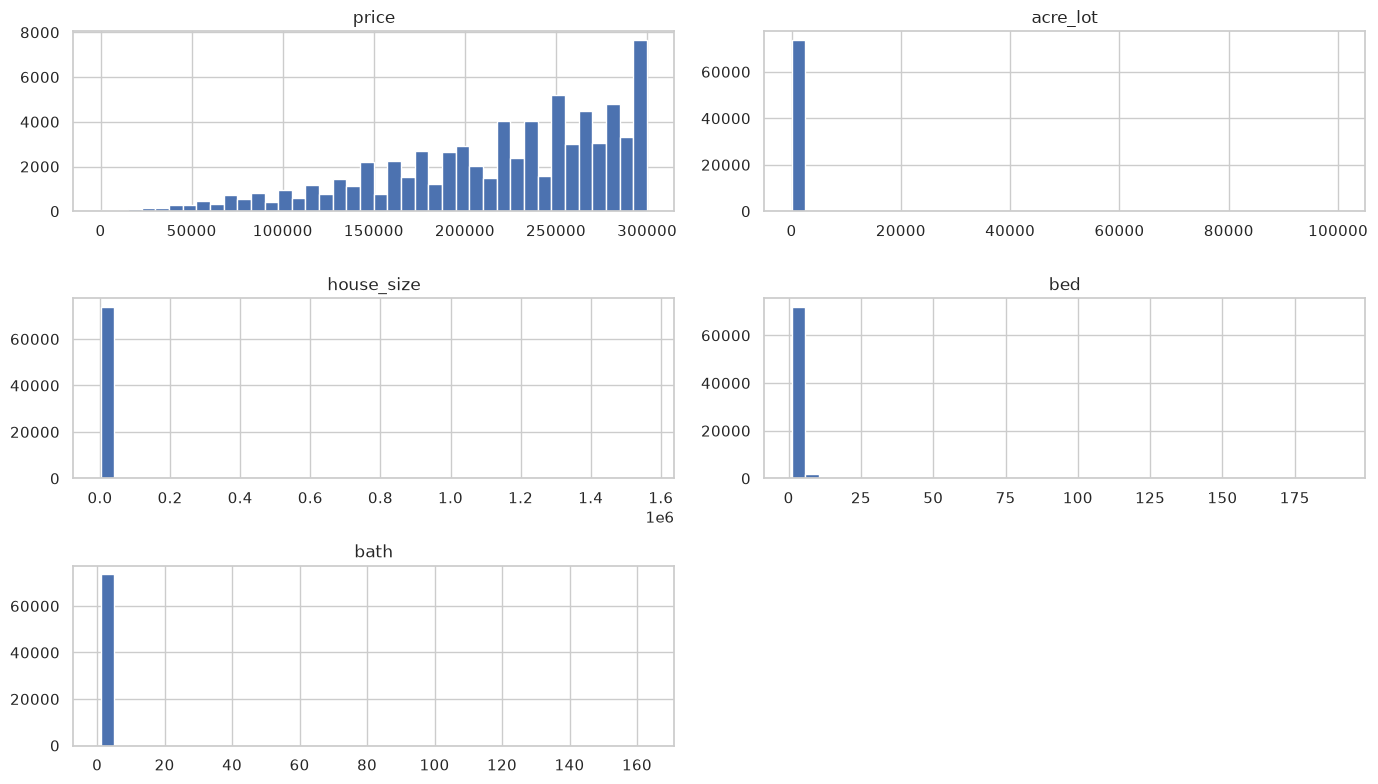

In [6]:
df[numeric].hist(bins=40, figsize=(14, 8))
plt.tight_layout()
plt.show()


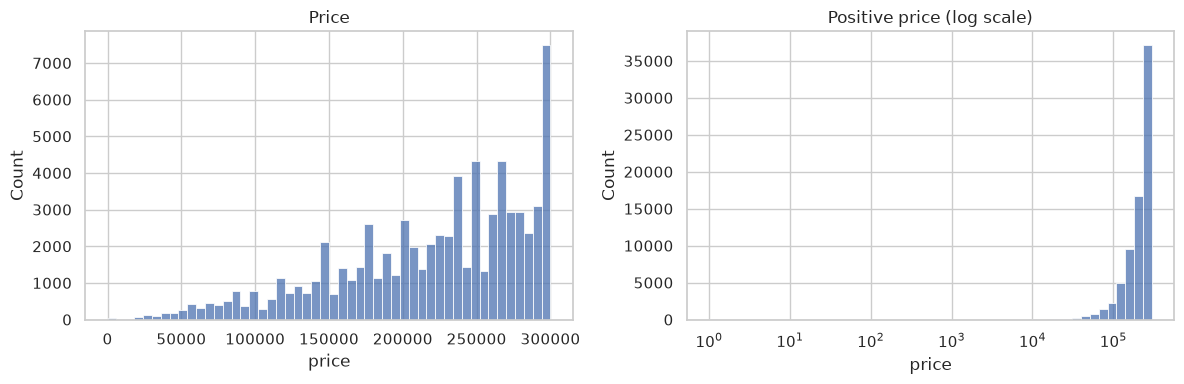

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df['price'].dropna(), bins=50, ax=axes[0])
axes[0].set_title('Price')
sns.histplot(df.loc[df.price.gt(0), 'price'], bins=50, log_scale=(True, False), ax=axes[1])
axes[1].set_title('Positive price (log scale)')
plt.tight_layout()
plt.show()


## Outliers (IQR)

Counts are indicators for investigation, not automatic removal rules.

,count,percent
price,342,0.46
acre_lot,10154,13.76
house_size,3690,5.00
bed,2077,2.81
bath,349,0.47


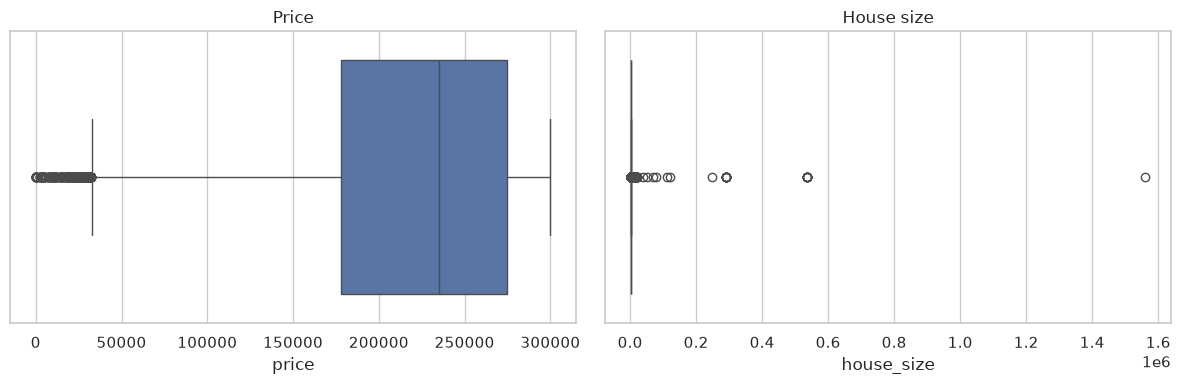

In [8]:
q1, q3 = df[numeric].quantile(.25), df[numeric].quantile(.75)
iqr = q3 - q1
outliers = (df[numeric].lt(q1 - 1.5 * iqr) | df[numeric].gt(q3 + 1.5 * iqr))
display(pd.DataFrame({'count': outliers.sum(), 'percent': outliers.mean().mul(100).round(2)}))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(x=df['price'], ax=axes[0]); axes[0].set_title('Price')
sns.boxplot(x=df['house_size'], ax=axes[1]); axes[1].set_title('House size')
plt.tight_layout()
plt.show()


## Categorical variables — text and numerical codes


In [9]:
for col in categorical:
    print(f'{col}: {df[col].nunique():,} categories')
    display(df[col].fillna('Missing').value_counts().head(10).rename_axis(col).reset_index(name='count'))


brokered_by: 20,856 categories


,brokered_by,count
0,22611.0,1046
1,53016.0,585
2,33714.0,407
3,79221.0,391
4,30807.0,330
5,33717.0,274
6,109987.0,262
7,109914.0,223
8,33745.0,223
9,15345.0,193


status: 1 categories


,status,count
0,for_sale,73784


street: 73,400 categories


,street,count
0,657038.0,3
1,1141294.0,3
2,943261.0,3
3,922112.0,3
4,673923.0,3
5,614546.0,3
6,765444.0,2
7,1009730.0,2
8,175243.0,2
9,269563.0,2


... (2 outputs left out)

state: 50 categories


,state,count
0,Texas,7645
1,Ohio,6239
2,Pennsylvania,4378
3,Georgia,4271
4,Illinois,4218
5,New York,4131
6,Florida,3814
7,Minnesota,2925
8,Michigan,2622
9,Oklahoma,2572


zip_code: 12,800 categories


,zip_code,count
0,44118.0,118
1,30058.0,110
2,28546.0,107
3,44102.0,87
4,73099.0,86
5,76549.0,85
6,12180.0,84
7,44120.0,83
8,44105.0,82
9,34473.0,81


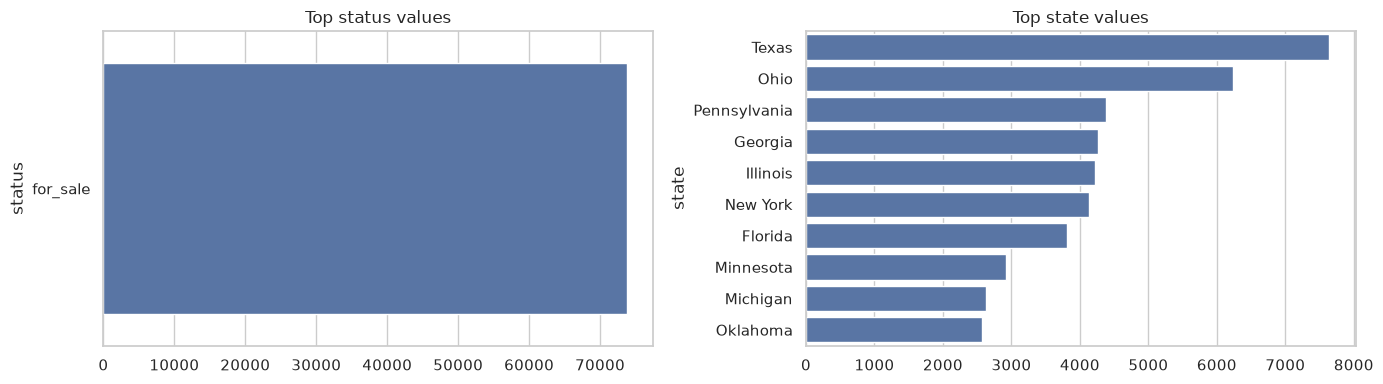

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, col in zip(axes, ['status', 'state']):
    counts = df[col].fillna('Missing').value_counts().head(10)
    sns.barplot(x=counts.values, y=counts.index, ax=ax)
    ax.set_title(f'Top {col} values')
plt.tight_layout()
plt.show()


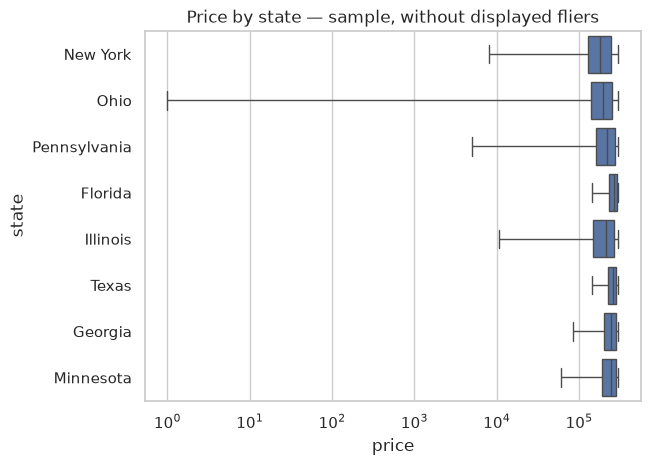

In [11]:
top_states = df['state'].value_counts().head(8).index
plot_data = df[df['state'].isin(top_states) & df['price'].gt(0)]
sns.boxplot(data=plot_data.sample(min(len(plot_data), 10000), random_state=42), x='price', y='state', showfliers=False)
plt.xscale('log')
plt.title('Price by state — sample, without displayed fliers')
plt.show()


## Correlation and relationships

,price,acre_lot,house_size,bed,bath
price,1.000000,0.000935,-0.028801,-0.028020,0.199712
acre_lot,0.000935,1.000000,-0.000007,0.009075,0.003170
house_size,-0.028801,-0.000007,1.000000,0.029943,0.035928
bed,-0.028020,0.009075,0.029943,1.000000,0.577265
bath,0.199712,0.003170,0.035928,0.577265,1.000000


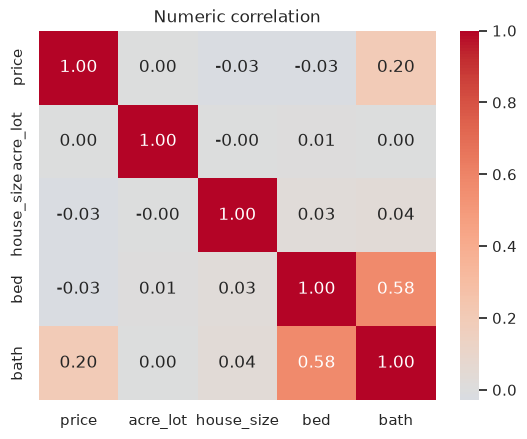

In [12]:
correlation = df[numeric].corr()
display(correlation)
sns.heatmap(correlation, annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Numeric correlation')
plt.show()


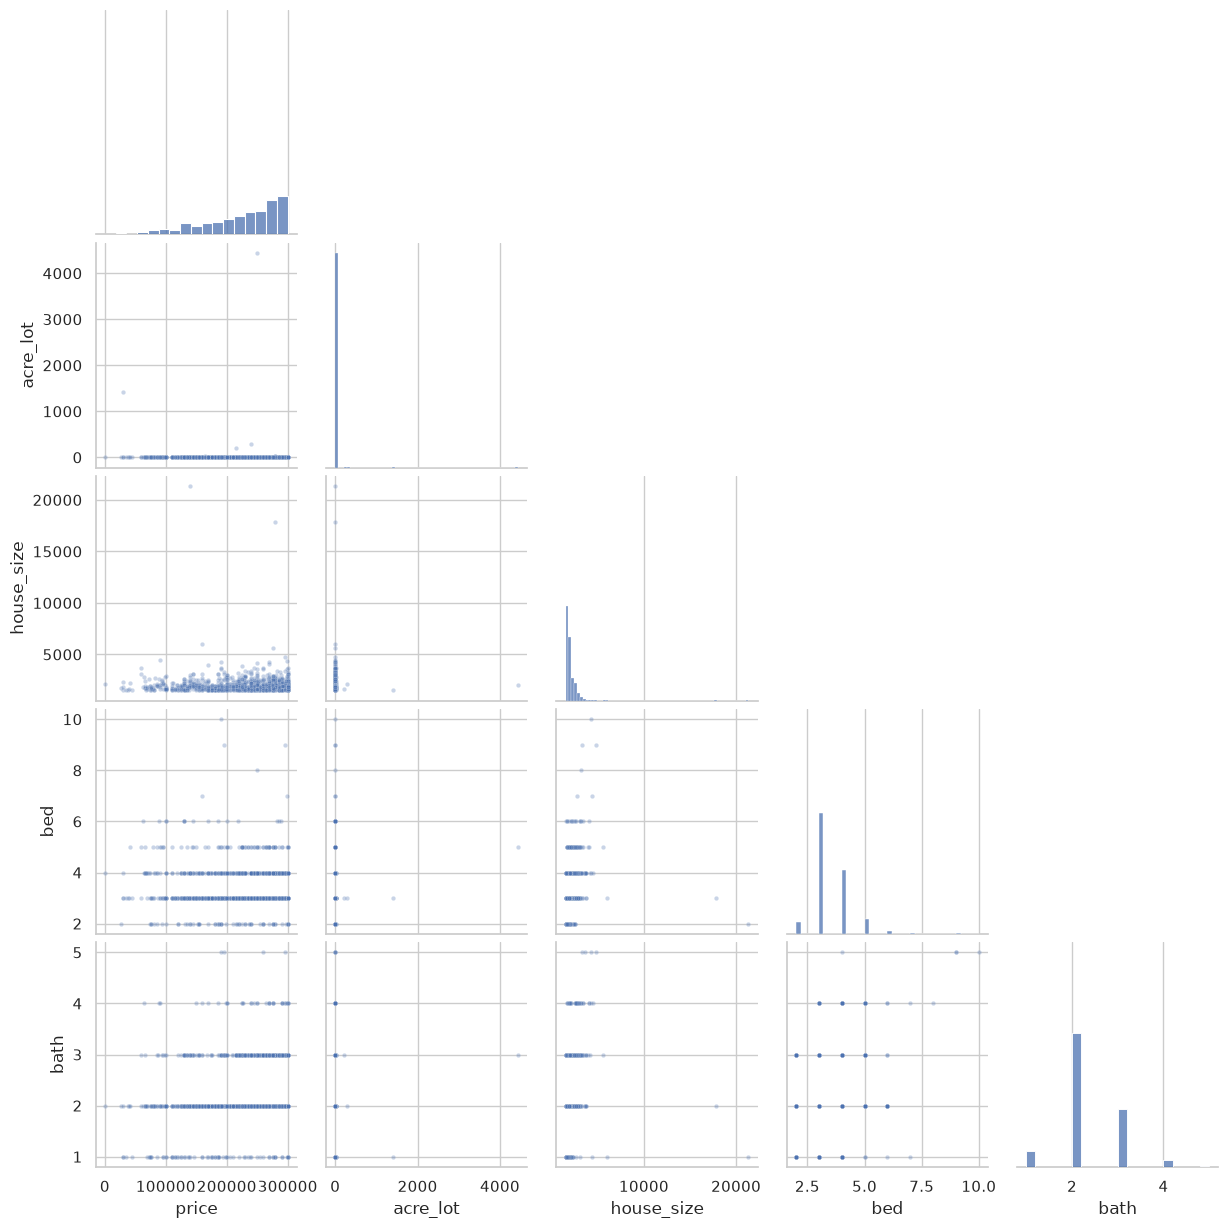

In [13]:
sample = df[numeric].dropna().sample(n=min(1000, len(df[numeric].dropna())), random_state=42)
sns.pairplot(sample, corner=True, plot_kws={'alpha': .3, 's': 10})
plt.show()


## Previous sale date


Missing or invalid dates: 0
Date range: 1904-03-18 00:00:00 to 2026-04-08 00:00:00


,year,count
0,2005,2060
1,2006,2365
2,2007,2119
3,2008,1841
4,2009,1782
5,2010,1733
6,2011,1594
7,2012,1855
8,2013,2344
9,2014,2679


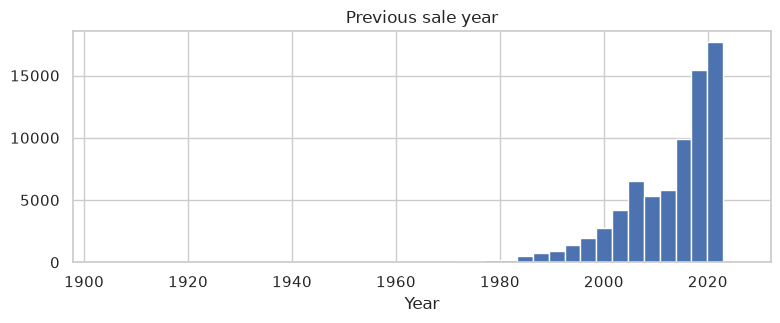

In [14]:
sold_date = pd.to_datetime(df['prev_sold_date'], errors='coerce')
print('Missing or invalid dates:', sold_date.isna().sum())
print('Date range:', sold_date.min(), 'to', sold_date.max())
display(sold_date.dt.year.value_counts().sort_index().tail(20).rename_axis('year').reset_index(name='count'))
sold_date.dt.year.hist(bins=40, figsize=(9, 3))
plt.title('Previous sale year')
plt.xlabel('Year')
plt.show()
